# Week 1: PAIRS TRADING & STATISTICAL ARBITRAGE - MEDIUM FREQUENCY TRADING
*Heiley Wong*

# Task 1: Daily Data Storage

## 1. Set Up
- Install packages
- Connect to Mongodb

In [1]:
import yfinance as yf
import pandas as pd
from pymongo import MongoClient, UpdateOne
import sys
import akshare as ak
from pymongo.mongo_client import MongoClient
from pymongo.server_api import ServerApi

In [2]:
import os
uri = os.environ["MONGODB_URI"]

client = MongoClient(uri, server_api=ServerApi('1'))

try:
    client.admin.command('ping')
    print("Pinged your deployment. You successfully connected to MongoDB!")
except Exception as e:
    print(e)

Pinged your deployment. You successfully connected to MongoDB!


In [3]:
db = client["sse_stock_db"]        
collection = db["daily_data"]      
meta = db["fetch_status"]          # to track completed stocks

## 2. Get lists of stocks traded in SSE
- Use AKShare to fetch codes of stocks traded in Shanghai stock exchange 

In [4]:
stocks = ak.stock_info_sh_name_code()
codes = stocks["证券代码"].astype(str).tolist()

print(f"Total SSE stocks: {len(codes)}")

Total SSE stocks: 1700


## 3. Import data
- Define functions to fetch stock data from Yahoo Finance, then import to database
- Data imported: Date, open, high, low, close, volume
- Data starts from 2010-01-01

In [5]:
def log(msg):
    print(msg)
    sys.stdout.flush()

# Check if stock is already imported
def is_complete(ticker):
    status = meta.find_one({"ticker": ticker})
    return status is not None and status.get("completed", False)

# Fetch data from yfinance
def fetch_one(code):
    # Convert to standard SSE form in yfinance
    ticker = code + ".SS"

    # Check if data already exists in databse
    if is_complete(ticker):
        log(f"Skipping {code}, already completed")
        return

    try:
        log(f"Fetching {code} ...")
        df = yf.download(ticker, start="2010-01-01", progress=False)
        if df.empty:
            log(f"No data for {code}")
            return

        # Reset index to get 'Date' as column
        df = df.reset_index()

        # Fix MultiIndex column if exists
        if isinstance(df.columns, pd.MultiIndex):
            df.columns = [c[0] if isinstance(c, tuple) else c for c in df.columns]

        # Rename to standard columns
        df.rename(columns={
            "Date": "date",
            "Open": "open",
            "High": "high",
            "Low": "low",
            "Close": "close",
            "Adj Close": "adj_close",
            "Volume": "volume"
        }, inplace=True)

        df["ticker"] = ticker

        # Print first 2 rows
        print(df.head(2))

        # Build bulk ops to Mongodb
        ops = [
            UpdateOne(
                {"ticker": r["ticker"], "date": r["date"]},
                {"$set": r},
                upsert=True
            )
            for r in df.to_dict("records")
        ]

        if ops:
            collection.bulk_write(ops, ordered=False)
            log(f"  ✅ Inserted {len(ops)} records for {code}")

        # Mark completion
        meta.update_one(
            {"ticker": ticker},
            {"$set": {"completed": True, "rows": len(df)}},
            upsert=True
        )

    except Exception as e:
        log(f" Failed {code}: {e}")

In [93]:
# Run sequentially
for code in codes:
    fetch_one(code)

⏭️ Skipping 600000, already completed
⏭️ Skipping 600004, already completed
⏭️ Skipping 600006, already completed
⏭️ Skipping 600007, already completed
⏭️ Skipping 600008, already completed
⏭️ Skipping 600009, already completed
⏭️ Skipping 600010, already completed
⏭️ Skipping 600011, already completed
⏭️ Skipping 600012, already completed
⏭️ Skipping 600015, already completed
⏭️ Skipping 600016, already completed
⏭️ Skipping 600017, already completed
⏭️ Skipping 600018, already completed
⏭️ Skipping 600019, already completed
⏭️ Skipping 600020, already completed
⏭️ Skipping 600021, already completed
⏭️ Skipping 600022, already completed
⏭️ Skipping 600023, already completed
⏭️ Skipping 600025, already completed
⏭️ Skipping 600026, already completed
⏭️ Skipping 600027, already completed
⏭️ Skipping 600028, already completed
⏭️ Skipping 600029, already completed
⏭️ Skipping 600030, already completed
⏭️ Skipping 600031, already completed
⏭️ Skipping 600032, already completed
⏭️ Skipping 

KeyboardInterrupt: 

### Check imported stocks
797 out of 1700 due to storage limitation in MongoDB. 

In [6]:
done_tickers = set(collection.distinct("ticker"))
print(f"Already in DB: {len(done_tickers)} tickers")

Already in DB: 797 tickers


## 4. REST API
- Return time series when given start date, end date, ticker, and desired fields

In [7]:
from fastapi import FastAPI, Query
from typing import Optional, List
import nest_asyncio
import uvicorn
from pymongo import MongoClient
from datetime import datetime
import pandas as pd
import threading

In [8]:
app = FastAPI(title="SSE Historical Data API")

def parse_date_field(doc):
    """Convert date field to ISO string for JSON"""
    d = doc.get("date")
    if hasattr(d, "isoformat"):
        doc["date"] = d.isoformat()
    return doc

@app.get("/prices")
def prices(
    ticker: str,
    start_date: str,
    end_date: str,
    fields: Optional[str] = Query(None, description="Comma-separated fields like high,low,volume")
):
    # Parse dates
    try:
        start_dt = pd.to_datetime(start_date)
        end_dt = pd.to_datetime(end_date)
    except Exception:
        return {"error": "Invalid start_date or end_date format. Use YYYY-MM-DD."}

    # Query MongoDB
    query = {
        "ticker": ticker,
        "date": {"$gte": start_dt, "$lte": end_dt}
    }
    cursor = collection.find(query)

    # Convert to DataFrame
    df = pd.DataFrame(list(cursor))
    if df.empty:
        return {"error": f"No data found for {ticker} in the given date range."}

    # Drop MongoDB _id field if exists
    if "_id" in df.columns:
        df.drop(columns=["_id"], inplace=True)

    # Filter requested fields
    if fields:
        requested = [f.strip() for f in fields.split(",")]
        # Always include 'date' and 'ticker'
        requested = [c for c in requested if c in df.columns]
        requested = ["date", "ticker"] + requested
        df = df[requested]

    # Convert dates to string for JSON
    df["date"] = df["date"].dt.strftime("%Y-%m-%d")

    return df.to_dict(orient="records")

In [9]:
nest_asyncio.apply()  # Allow async in notebook

def run_api():
    uvicorn.run(app, host="127.0.0.1", port=8000, log_level="info")

# Run in a separate thread so notebook stays interactive
thread = threading.Thread(target=run_api, daemon=True)
thread.start()

INFO:     Started server process [1856]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://127.0.0.1:8000 (Press CTRL+C to quit)


INFO:     127.0.0.1:50089 - "GET / HTTP/1.1" 404 Not Found
INFO:     127.0.0.1:50089 - "GET /favicon.ico HTTP/1.1" 404 Not Found
INFO:     127.0.0.1:50091 - "GET /docs HTTP/1.1" 200 OK
INFO:     127.0.0.1:50091 - "GET /openapi.json HTTP/1.1" 200 OK
INFO:     127.0.0.1:50113 - "GET /prices?ticker=600000.SS&start_date=2010-01-04&end_date=2010-01-05&fields=high%2Clow%2Cvolume HTTP/1.1" 200 OK


# 5. Daily Update

1. Cron scheduler is configured once using `crontab -e`.
2. At 16:30 China time, Monday–Friday, cron automatically triggers the job.
3. Cron runs `run_daily_update.sh`.
4. The shell script activates the Python environment and executes `update_daily.py`.
5. `update_daily.py` fetches only new market data and upserts it into MongoDB.
6. Logs are written for monitoring.

`update_daily.py`

In [ ]:
import sys
import datetime
import yfinance as yf
import pandas as pd
from pymongo import UpdateOne

# reuse your logger
def log(msg):
    print(msg)
    sys.stdout.flush()

def get_last_date(ticker):
    doc = collection.find_one(
        {"ticker": ticker},
        sort=[("date", -1)],
        projection={"date": 1}
    )
    return doc["date"] if doc else None

def update_one(code):
    ticker = code + ".SS"

    try:
        last_date = get_last_date(ticker)

        if last_date:
            start = (last_date + datetime.timedelta(days=1)).strftime("%Y-%m-%d")
            log(f"Updating {code} from {start}")
        else:
            start = "2010-01-01"
            log(f"No history found for {code}, doing full fetch")

        df = yf.download(
            ticker,
            start=start,
            progress=False,
            auto_adjust=False
        )

        if df.empty:
            log(f"No new data for {code}")
            return

        df = df.reset_index()

        if isinstance(df.columns, pd.MultiIndex):
            df.columns = [c[0] for c in df.columns]

        df.rename(columns={
            "Date": "date",
            "Open": "open",
            "High": "high",
            "Low": "low",
            "Close": "close",
            "Adj Close": "adj_close",
            "Volume": "volume"
        }, inplace=True)

        df["ticker"] = ticker

        ops = [
            UpdateOne(
                {"ticker": r["ticker"], "date": r["date"]},
                {"$set": r},
                upsert=True
            )
            for r in df.to_dict("records")
        ]

        if ops:
            collection.bulk_write(ops, ordered=False)
            log(f"{code}: {len(ops)} rows updated")

    except Exception as e:
        log(f"Failed {code}: {e}")

def main():
    tickers = meta.find({}, {"ticker": 1})
    for t in tickers:
        code = t["ticker"].replace(".SS", "")
        update_one(code)

if __name__ == "__main__":
    main()

`run_daily_update.sh`

In terminal, run

# Task 2: Mean-reversion Strategy

## 1.  Set Up

In [1]:
import pandas as pd
import numpy as np
from pymongo import MongoClient
from pymongo.server_api import ServerApi
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import squareform
from sklearn.cluster import DBSCAN, OPTICS, KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

## 2. Import data
Testing with 50 stocks. 

In [4]:
# Load selected tickers
tickers = collection.distinct("ticker")[:50]

dfs = []
for t in tickers:
    # fetch data
    docs = list(collection.find({"ticker": t}, {"_id":0, "date":1, "close":1}))
    
    if not docs:
        continue

    # flatten MongoDB date field
    for d in docs:
        if isinstance(d["date"], dict) and "$date" in d["date"]:
            d["date"] = pd.to_datetime(d["date"]["$date"])

    # convert to DataFrame
    df = pd.DataFrame(docs)
    
    # rename close column to ticker
    df.rename(columns={"close": t}, inplace=True)

    # ensure date column is datetime and set index
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")
    
    dfs.append(df)

# Merge all tickers
if dfs:
    data = pd.concat(dfs, axis=1).sort_index()
    data = data.fillna(method="ffill").dropna()
else:
    data = pd.DataFrame()

/var/folders/br/2ygwq5cd58q90bxlwkl2zz580000gn/T/ipykernel_21968/1081233848.py:35: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data = data.fillna(method="ffill").dropna()


## 3. Calculate correlation matrix

Pandas computes the Pearson correlation coefficient by default.

$$\rho_{X,Y}
=
\frac{\operatorname{Cov}(X,Y)}{\sigma_X \sigma_Y}
=
\frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}
{\sqrt{\sum_{i=1}^{n} (x_i - \bar{x})^2}
 \sqrt{\sum_{i=1}^{n} (y_i - \bar{y})^2}}
$$

- $\operatorname{Cov}(X,Y)$: Covariance between series X and series Y
- $\sigma_X$: Standard deviation of series X
- $x_1, y_i$: Values of X and Y at time i
- $\bar{x}$: Mean value of series X or Y
- $n$: Number of time periods
  
**Interpretation**

- $\rho = 1$: Perfect positive linear relationship  
- $\rho = -1$: Perfect negative linear relationship  
- $\rho = 0$: No linear relationship  

In [5]:
returns = data.pct_change().dropna()
corr_matrix = returns.corr()
print(corr_matrix)

           600000.SS  600004.SS  600006.SS  600007.SS  600008.SS  600009.SS  \
600000.SS   1.000000   0.248425   0.129749   0.267684   0.335868   0.266588   
600004.SS   0.248425   1.000000   0.199589   0.208960   0.359061   0.778995   
600006.SS   0.129749   0.199589   1.000000   0.133130   0.283385   0.194797   
600007.SS   0.267684   0.208960   0.133130   1.000000   0.361008   0.182865   
600008.SS   0.335868   0.359061   0.283385   0.361008   1.000000   0.332818   
600009.SS   0.266588   0.778995   0.194797   0.182865   0.332818   1.000000   
600010.SS   0.171430   0.201251   0.277787   0.214142   0.445810   0.241115   
600011.SS   0.128645   0.128427   0.065663   0.150594   0.339988   0.123037   
600012.SS   0.293815   0.206497   0.074932   0.222121   0.375307   0.148869   
600015.SS   0.680878   0.231667   0.136506   0.294756   0.416252   0.227039   
600016.SS   0.618663   0.221128   0.169322   0.293161   0.399040   0.223930   
600017.SS   0.360543   0.387352   0.249363   0.34128

## 4. Enhanced clustering methods
Here we compare 4 different clustering methods based on the correlation matrix calculated above. 

### Methods

All methods operate on a **distance matrix** derived from correlations.

$$
d_{ij} = \left( 1 - |\rho_{ij}| \right)^{p}
$$

- $ \rho_{ij} $: Pearson correlation between stocks $i$ and $j$  
- $ |\rho_{ij}| $: Absolute correlation (focuses on strength, not sign)  
- $ p $: `distance_power`, controls emphasis on strong correlations  
- $ d_{ij} \in [0,1] $: Distance between stocks $i$ and $j$

---

1. **Hierarchical Clustering**

Ward Linkage (example)

$$
\Delta(A, B) =
\frac{|A||B|}{|A| + |B|}
\left\| \mu_A - \mu_B \right\|^2
$$

- $A, B$: Two clusters
- $|A|, |B|$: Cluster sizes
- $\mu_A, \mu_B$: Cluster centroids
 
Builds a tree (dendrogram) by iteratively merging clusters that minimize within-cluster variance. Final clusters are obtained by cutting the tree at a distance threshold or fixed number of clusters.

---

2. **DBSCAN (Density-Based Spatial Clustering)**

Core Point Condition

$$
\left| \{ j : d_{ij} \le \varepsilon \} \right|
\ge \text{min\_samples}
$$

- $ \varepsilon $: Neighborhood radius (`eps`)
- `min_samples`: Minimum points to form a dense region
 
Groups stocks that lie in dense regions of the distance space. Does not require specifying the number of clusters and can identify noise (outliers).

---

3. **OPTICS (Ordering Points To Identify Clustering Structure)**

Reachability Distance

$$
\text{reachability}(i, j) =
\max \left( \text{core\_dist}(i),\ d_{ij} \right)
$$

- $ d_{ij} $: Distance between points
- $ \text{core\_dist}(i) $: Minimum radius to make $i$ a core point

Generalizes DBSCAN by exploring clustering structure over multiple density levels. Suitable when clusters have varying densities.

---

4. **K-Means (on PCA-Reduced Data)**

Objective Function

$$
\min_{\{C_k\}} \sum_{k=1}^{K} \sum_{x_i \in C_k}
\left\| x_i - \mu_k \right\|^2
$$

- $K$: Number of clusters
- $x_i$: Feature vector of stock $i$ (PCA-transformed)
- $\mu_k$: Centroid of cluster $k$

Clusters stocks by minimizing within-cluster squared distances. PCA is applied first to reduce dimensionality and noise in the correlation matrix.

---

Summary

| Method | Requires $K$? | Handles Noise | Key Strength |
|------|----------------|---------------|--------------|
| Hierarchical | Optional | No | Interpretable structure (dendrogram) |
| DBSCAN | No | Yes | Finds arbitrary-shaped clusters |
| OPTICS | No | Yes | Handles varying densities |
| K-Means | Yes | No | Fast and scalable |

### Code

In [ ]:
def enhanced_stock_clustering(corr_matrix, method='hierarchical', n_clusters=None, 
                             distance_power=1.0, min_cluster_size=3, visualize=True):

    # Clean correlation matrix (handle NaN, ensure symmetric)
    corr_matrix = corr_matrix.fillna(0)
    corr_matrix = (corr_matrix + corr_matrix.T) / 2  # Ensure symmetry
    np.fill_diagonal(corr_matrix.values, 1.0)
    
    # Enhanced distance metric
    # Using absolute correlation to focus on magnitude of relationship
    abs_corr = corr_matrix.abs()
    distance = (1 - abs_corr) ** distance_power
    
    # Convert to condensed distance vector
    condensed_dist = squareform(distance.values, checks=False)
    
    # Determine optimal number of clusters if not specified
    if n_clusters is None:
        # Use elbow method on hierarchical clustering
        linked = linkage(condensed_dist, method='ward')
        
        # Calculate distances between successive merges
        last_merges = linked[-20:, 2]  # Last 20 merge distances
        diffs = np.diff(last_merges)
        diffs_ratio = diffs[1:] / diffs[:-1]
        
        # Find elbow point (largest relative change)
        if len(diffs_ratio) > 0:
            elbow_idx = np.argmax(diffs_ratio) + 2  # +2 for indexing
            n_clusters = max(2, min(10, len(corr_matrix) // 5, elbow_idx))
        else:
            n_clusters = max(2, min(10, len(corr_matrix) // 10))
    
    # Method 1: Hierarchical Clustering with different linkage methods
    if method in ['hierarchical', 'best']:
        linkage_methods = ['ward', 'average', 'complete', 'weighted']
        best_score = -1
        best_clusters = None
        best_method = None
        
        for linkage_method in linkage_methods:
            try:
                linked = linkage(condensed_dist, method=linkage_method)
                
                # Try different thresholds for optimal clustering
                if method == 'best':
                    # Test multiple thresholds
                    thresholds = np.linspace(0.3, 0.8, 6)
                    for t in thresholds:
                        clusters = fcluster(linked, t=t, criterion='distance')
                        unique_clusters = len(set(clusters))
                        
                        if 1 < unique_clusters < len(corr_matrix) // 2:
                            # Calculate silhouette score
                            if len(set(clusters)) > 1:
                                score = silhouette_score(distance.values, clusters, 
                                                        metric='precomputed')
                                if score > best_score:
                                    best_score = score
                                    best_clusters = clusters
                                    best_method = f"{linkage_method}_t={t:.2f}"
                else:
                    # Fixed number of clusters
                    clusters = fcluster(linked, t=n_clusters, criterion='maxclust')
                    if len(set(clusters)) > 1:
                        score = silhouette_score(distance.values, clusters, 
                                                metric='precomputed')
                        if score > best_score:
                            best_score = score
                            best_clusters = clusters
                            best_method = linkage_method
            except:
                continue
        
        if best_clusters is not None:
            clusters = best_clusters
            print(f"Best hierarchical method: {best_method} (Silhouette: {best_score:.3f})")
        else:
            # Fallback to average linkage
            linked = linkage(condensed_dist, method='average')
            clusters = fcluster(linked, t=0.5, criterion='distance')
    
    # Method 2: DBSCAN (density-based)
    elif method == 'dbscan':
        # Auto-tune DBSCAN parameters
        eps_values = np.linspace(0.3, 0.7, 5)
        min_samples_values = [2, 3, 4]
        
        best_score = -1
        best_clusters = None
        
        for eps in eps_values:
            for min_samples in min_samples_values:
                dbscan = DBSCAN(eps=eps, min_samples=min_samples, 
                              metric='precomputed')
                cluster_labels = dbscan.fit_predict(distance.values)
                
                # Convert -1 (noise) to separate clusters
                unique_labels = set(cluster_labels)
                if -1 in unique_labels:
                    # Assign noise points to new clusters
                    max_label = max([l for l in unique_labels if l != -1] or [0])
                    noise_mask = cluster_labels == -1
                    cluster_labels[noise_mask] = range(max_label + 1, 
                                                       max_label + 1 + sum(noise_mask))
                
                if len(set(cluster_labels)) > 1:
                    score = silhouette_score(distance.values, cluster_labels, 
                                           metric='precomputed')
                    if score > best_score:
                        best_score = score
                        best_clusters = cluster_labels
        
        clusters = best_clusters if best_clusters is not None else np.zeros(len(corr_matrix))
    
    # Method 3: OPTICS
    elif method == 'optics':
        optics = OPTICS(min_samples=min_cluster_size, metric='precomputed',
                       cluster_method='xi')
        clusters = optics.fit_predict(distance.values)
        
        # Handle noise points
        if -1 in clusters:
            # Assign noise to new clusters
            max_cluster = clusters.max()
            noise_mask = clusters == -1
            clusters[noise_mask] = range(max_cluster + 1, 
                                        max_cluster + 1 + sum(noise_mask))
    
    # Method 4: K-means on PCA components
    elif method == 'kmeans':
        # Reduce dimensionality with PCA
        pca = PCA(n_components=min(10, len(corr_matrix)))
        features = pca.fit_transform(corr_matrix.values)
        
        # Determine optimal k using elbow method
        if n_clusters is None:
            inertias = []
            max_k = min(15, len(corr_matrix) // 2)
            for k in range(2, max_k + 1):
                kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
                kmeans.fit(features)
                inertias.append(kmeans.inertia_)
            
            # Find elbow point
            diffs = np.diff(inertias)
            diffs_ratio = diffs[1:] / diffs[:-1]
            if len(diffs_ratio) > 0:
                n_clusters = np.argmin(diffs_ratio) + 3
            else:
                n_clusters = 5
        
        kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
        clusters = kmeans.fit_predict(features)
        print(f"K-means on {pca.n_components_} PCA components "
              f"(explained variance: {pca.explained_variance_ratio_.sum():.2%})")
    
    # Create cluster DataFrame
    cluster_df = pd.DataFrame({
        "ticker": corr_matrix.columns,
        "cluster": clusters
    })
    
    # Filter small clusters
    cluster_sizes = cluster_df['cluster'].value_counts()
    valid_clusters = cluster_sizes[cluster_sizes >= min_cluster_size].index
    cluster_df = cluster_df[cluster_df['cluster'].isin(valid_clusters)]
    
    # Renumber clusters sequentially
    cluster_mapping = {old: new for new, old in enumerate(sorted(cluster_df['cluster'].unique()))}
    cluster_df['cluster'] = cluster_df['cluster'].map(cluster_mapping)
    
    # Calculate clustering metrics
    if len(cluster_df['cluster'].unique()) > 1:
        # Filter distance matrix to only include valid clusters
        valid_tickers = cluster_df['ticker'].values
        valid_distance = distance.loc[valid_tickers, valid_tickers]
        
        silhouette = silhouette_score(valid_distance.values, 
                                    cluster_df['cluster'].values, 
                                    metric='precomputed')
        calinski = calinski_harabasz_score(valid_distance.values, 
                                         cluster_df['cluster'].values)
        
        print(f"\nClustering Performance Metrics:")
        print(f"Number of clusters: {len(cluster_df['cluster'].unique())}")
        print(f"Silhouette Score: {silhouette:.3f} "
              f"(-1 to 1, higher is better)")
        print(f"Calinski-Harabasz Score: {calinski:.1f} "
              f"(higher is better)")
        
        # Intra-cluster correlation statistics
        print(f"\nCluster Statistics:")
        for cluster_id in sorted(cluster_df['cluster'].unique()):
            cluster_tickers = cluster_df[cluster_df['cluster'] == cluster_id]['ticker'].tolist()
            if len(cluster_tickers) > 1:
                cluster_corr = corr_matrix.loc[cluster_tickers, cluster_tickers]
                intra_corr = cluster_corr.values[np.triu_indices_from(cluster_corr.values, k=1)]
                print(f"Cluster {cluster_id}: {len(cluster_tickers)} stocks, "
                      f"Avg intra-correlation: {intra_corr.mean():.3f}")
    
    # Visualization
    if visualize and len(cluster_df) > 0:
        visualize_clustering_results(corr_matrix, cluster_df, distance)
    
    return cluster_df

In [ ]:
def visualize_clustering_results(corr_matrix, cluster_df, distance):
    """Visualize clustering results"""
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    
    # Sort tickers by cluster for better visualization
    cluster_df_sorted = cluster_df.sort_values('cluster')
    sorted_tickers = cluster_df_sorted['ticker'].values
    
    # 1. Correlation heatmap (clustered)
    corr_sorted = corr_matrix.loc[sorted_tickers, sorted_tickers]
    im1 = axes[0, 0].imshow(corr_sorted.values, cmap='coolwarm', vmin=-1, vmax=1, 
                           aspect='auto')
    axes[0, 0].set_title('Correlation Matrix (Clustered)')
    axes[0, 0].set_xlabel('Stocks')
    axes[0, 0].set_ylabel('Stocks')
    plt.colorbar(im1, ax=axes[0, 0])
    
    # Add cluster boundaries
    cluster_bounds = np.where(np.diff(cluster_df_sorted['cluster'].values) != 0)[0]
    for bound in cluster_bounds:
        axes[0, 0].axhline(y=bound + 0.5, color='black', linewidth=2, alpha=0.7)
        axes[0, 0].axvline(x=bound + 0.5, color='black', linewidth=2, alpha=0.7)
    
    # 2. Distance matrix
    distance_sorted = distance.loc[sorted_tickers, sorted_tickers]
    im2 = axes[0, 1].imshow(distance_sorted.values, cmap='viridis', aspect='auto')
    axes[0, 1].set_title('Distance Matrix (1 - |corr|)')
    axes[0, 1].set_xlabel('Stocks')
    axes[0, 1].set_ylabel('Stocks')
    plt.colorbar(im2, ax=axes[0, 1])
    
    # 3. Cluster sizes
    cluster_sizes = cluster_df['cluster'].value_counts().sort_index()
    axes[0, 2].bar(range(len(cluster_sizes)), cluster_sizes.values, 
                  color=plt.cm.tab20.colors[:len(cluster_sizes)])
    axes[0, 2].set_title('Cluster Sizes')
    axes[0, 2].set_xlabel('Cluster ID')
    axes[0, 2].set_ylabel('Number of Stocks')
    axes[0, 2].set_xticks(range(len(cluster_sizes)))
    axes[0, 2].set_xticklabels(cluster_sizes.index)
    
    # 4. Intra-cluster correlation distribution
    intra_corrs = []
    for cluster_id in cluster_df['cluster'].unique():
        cluster_tickers = cluster_df[cluster_df['cluster'] == cluster_id]['ticker'].tolist()
        if len(cluster_tickers) > 1:
            cluster_corr = corr_matrix.loc[cluster_tickers, cluster_tickers]
            intra_corr = cluster_corr.values[np.triu_indices_from(cluster_corr.values, k=1)]
            intra_corrs.extend(intra_corr)
    
    axes[1, 0].hist(intra_corrs, bins=30, edgecolor='black', alpha=0.7)
    axes[1, 0].axvline(x=np.mean(intra_corrs), color='red', linestyle='--', 
                      label=f'Mean: {np.mean(intra_corrs):.3f}')
    axes[1, 0].set_title('Distribution of Intra-cluster Correlations')
    axes[1, 0].set_xlabel('Correlation')
    axes[1, 0].set_ylabel('Frequency')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    
    # 5. Inter-cluster distance
    if len(cluster_df['cluster'].unique()) > 1:
        cluster_means = []
        for cluster_id in cluster_df['cluster'].unique():
            cluster_tickers = cluster_df[cluster_df['cluster'] == cluster_id]['ticker'].tolist()
            cluster_mean_corr = corr_matrix.loc[cluster_tickers].mean().mean()
            cluster_means.append(cluster_mean_corr)
        
        axes[1, 1].bar(range(len(cluster_means)), cluster_means, 
                      color=plt.cm.tab20.colors[:len(cluster_means)])
        axes[1, 1].set_title('Average Correlation within Clusters')
        axes[1, 1].set_xlabel('Cluster ID')
        axes[1, 1].set_ylabel('Average Correlation')
        axes[1, 1].set_xticks(range(len(cluster_means)))
        axes[1, 1].set_xticklabels(sorted(cluster_df['cluster'].unique()))
    
    # 6. Dendrogram (if hierarchical was used)
    try:
        linked = linkage(squareform(distance.values, checks=False), method='ward')
        dendrogram(linked, labels=corr_matrix.columns.tolist(), 
                  leaf_rotation=90, ax=axes[1, 2])
        axes[1, 2].set_title('Dendrogram')
        axes[1, 2].set_xlabel('Stocks')
        axes[1, 2].set_ylabel('Distance')
    except:
        axes[1, 2].text(0.5, 0.5, 'Dendrogram not available\nfor current method',
                       ha='center', va='center')
        axes[1, 2].set_title('Dendrogram')
    
    plt.tight_layout()
    plt.show()


## 5. Clustering

Best hierarchical method: ward_t=0.70 (Silhouette: 0.220)

Clustering Performance Metrics:
Number of clusters: 8
Silhouette Score: 0.235 (-1 to 1, higher is better)
Calinski-Harabasz Score: 9.5 (higher is better)

Cluster Statistics:
Cluster 0: 6 stocks, Avg intra-correlation: 0.476
Cluster 1: 10 stocks, Avg intra-correlation: 0.441
Cluster 2: 4 stocks, Avg intra-correlation: 0.614
Cluster 3: 6 stocks, Avg intra-correlation: 0.433
Cluster 4: 4 stocks, Avg intra-correlation: 0.606
Cluster 5: 5 stocks, Avg intra-correlation: 0.367
Cluster 6: 3 stocks, Avg intra-correlation: 0.304
Cluster 7: 5 stocks, Avg intra-correlation: 0.468


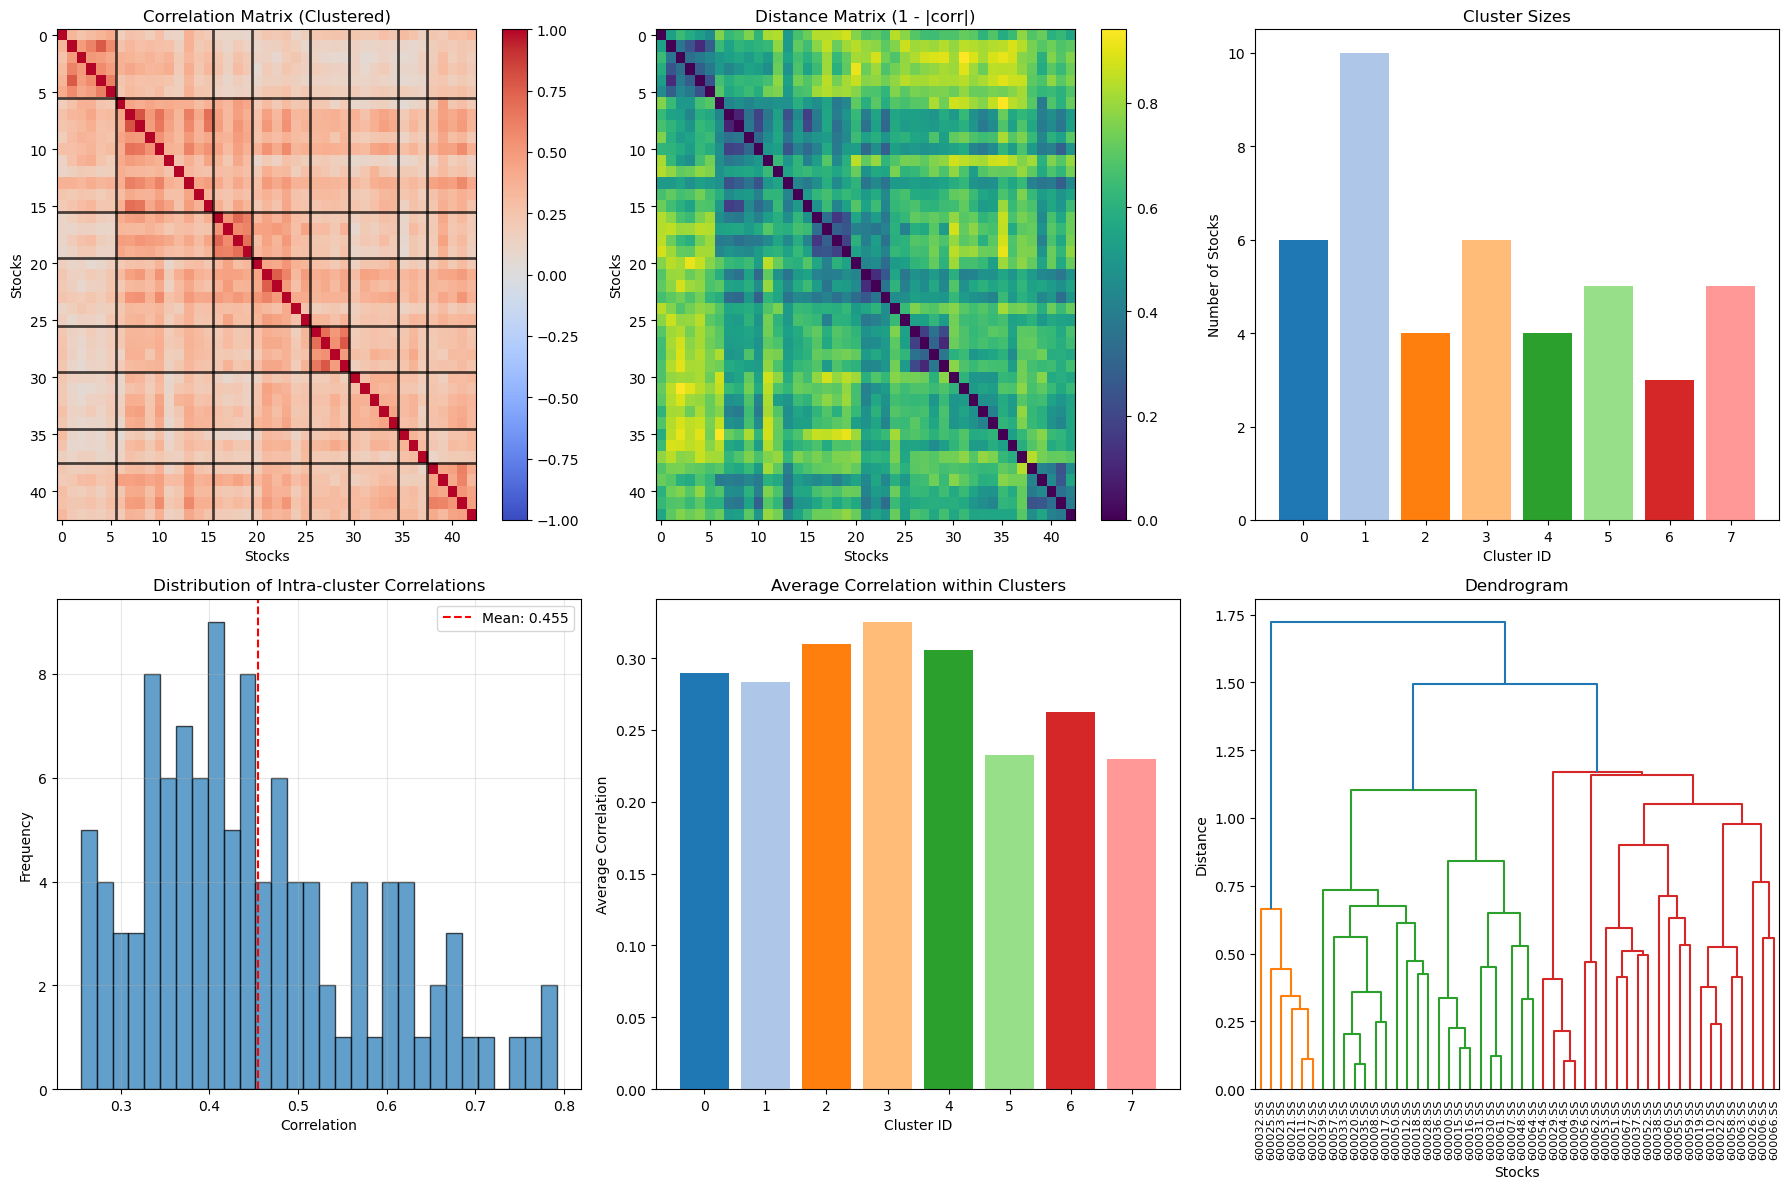


Final Cluster Assignments:
       ticker  cluster
0   600011.SS        0
1   600021.SS        0
2   600023.SS        0
3   600025.SS        0
4   600027.SS        0
5   600032.SS        0
6   600008.SS        1
7   600012.SS        1
8   600017.SS        1
9   600018.SS        1
10  600020.SS        1
11  600028.SS        1
12  600033.SS        1
13  600035.SS        1
14  600050.SS        1
15  600057.SS        1
16  600000.SS        2
17  600015.SS        2
18  600016.SS        2
19  600036.SS        2
20  600007.SS        3
21  600030.SS        3
22  600031.SS        3
23  600048.SS        3
24  600061.SS        3
25  600064.SS        3
26  600004.SS        4
27  600009.SS        4
28  600029.SS        4
29  600054.SS        4
30  600037.SS        5
31  600051.SS        5
32  600052.SS        5
33  600053.SS        5
34  600067.SS        5
35  600055.SS        6
36  600059.SS        6
37  600060.SS        6
38  600010.SS        7
39  600019.SS        7
40  600022.SS        7
41  60

In [7]:
# Clean returns data
returns_clean = returns.replace([np.inf, -np.inf], np.nan).dropna(axis=1)

# Calculate correlation matrix with minimum period requirement
min_periods = len(returns_clean) // 2  # Require at least 50% overlap
corr_matrix = returns_clean.corr(min_periods=min_periods)

# Fill remaining NaN with 0 (no correlation assumption)
corr_matrix = corr_matrix.fillna(0)

# Run enhanced clustering
cluster_df = enhanced_stock_clustering(
    corr_matrix=corr_matrix,
    method='best',  # Try all methods and pick best
    n_clusters=None,  # Auto-determine
    distance_power=1.5,  # Emphasize strong correlations
    min_cluster_size=3,  # Minimum 3 stocks per cluster
    visualize=True
)

print("\nFinal Cluster Assignments:")
print(cluster_df.sort_values(['cluster', 'ticker']).reset_index(drop=True))


## 6. Define strategy, backtest

This strategy trades individual stocks relative to their cluster peers, exploiting short-term deviations from a cluster mean. It is a market-neutral, mean-reversion strategy applied within statistically similar groups of stocks.

1. Trading is only performed within clusters
2. Cluster mean acts as a dynamic benchmark
3. Normalised spread (Z-score) definition

    For each stock \( i \) in cluster \( c \):
    $
    S_i(t) = P_i(t) - \mu_c(t)
    $
    
    - Positive spread: stock is expensive relative to peers  
    - Negative spread: stock is cheap relative to peers  
    
    The spread is standardized using a rolling window: $
    Z_i(t) =
    \frac{S_i(t) - \overline{S}_i(t)}
    {\sigma_{S_i}(t)}
    $
    
    where the rolling statistics are computed over 10 days. This measures how extreme the deviation is relative to recent history.

4. Trading signal generation
    - Go Long if: $Z_i(t) < -0.8$
    - Go Short if: $Z_i(t) > 0.8 $
    
    - Exit Long if: $Z_i(t) > -0.2$
    
    - Exit Short if: $Z_i(t) < 0.2$


5. Positions evolve according to a simple state machine:

    - \( +1 \): Long  
    - \( -1 \): Short  
    - \( 0 \): Flat  

    Only one position per stock is held at a time, and positions persist until explicit exit conditions are met.

6. Stop-Loss Risk Control

    A daily stop-loss is applied: $ r_i(t) \cdot \text{position}_i(t) < -\text{stop\_loss\_pct}  $
    
    - \( r_i(t) \): Daily return of stock \( i \)
    - Positions are immediately closed if losses exceed the threshold


7. Return Calculation
    
    Daily PnL per stock: $
    \text{PnL}_i(t) = r_i(t) \cdot \text{position}_i(t-1)
    $
    
    - Positions are lagged by one day to avoid look-ahead bias
    

#### Strategy Intuition

- Stocks within a cluster are assumed to be **temporarily mispriced relative to peers**
- Extreme deviations tend to revert toward the cluster mean
- The strategy profits from **relative-value convergence**, not market direction

### Key Assumptions

1. Stable Correlation Structure: Stocks within a cluster are assumed to maintain similar behavior over time, so historical correlations remain valid.

2. Mean Reversion Within Clusters: Deviations of a stock from its cluster mean are temporary and expected to revert toward zero.

3. Z-Score Stationarity: Rolling mean and volatility of spreads are assumed stable, so z-score signals reliably indicate over- or under-valuation.

4. Liquidity and Tradability: All stocks can be traded daily with minimal slippage and transaction costs, enabling realistic execution.

In [18]:
# Dictionary to store per-stock results
results = {}
positions_df = pd.DataFrame(index=data.index)

# Backtest loop over clusters
for c in cluster_df["cluster"].unique():
    cluster_stocks = cluster_df[cluster_df["cluster"] == c]["ticker"].tolist()
    
    # Filter tickers that exist in price data
    cluster_stocks = [t for t in cluster_stocks if t in data.columns]
    if len(cluster_stocks) < 2:
        continue
    
    cluster_prices = data[cluster_stocks]
    cluster_mean = cluster_prices.mean(axis=1)
    
    for t in cluster_stocks:
        # Spread and rolling z-score
        spread = cluster_prices[t] - cluster_mean
        zscore = (spread - spread.rolling(10).mean()) / spread.rolling(10).std()
        
        # Entry/exit thresholds with hysteresis
        long_entry = zscore < -0.8
        long_exit  = zscore > -0.2
        short_entry = zscore > 0.8
        short_exit  = zscore < 0.2
        
        # Generate positions with hysteresis
        positions = pd.Series(0, index=zscore.index)
        current_pos = 0
        for date in spread.index[1:]:
            if current_pos == 0:
                if long_entry.loc[date]:
                    current_pos = 1
                elif short_entry.loc[date]:
                    current_pos = -1
            elif current_pos == 1 and long_exit.loc[date]:
                current_pos = 0
            elif current_pos == -1 and short_exit.loc[date]:
                current_pos = 0
            
            # Stop-loss: safe access
            if current_pos != 0 and not pd.isna(returns[t].get(date)):
                daily_ret_val = returns[t].loc[date] * current_pos
                if daily_ret_val < -stop_loss_pct:
                    current_pos = 0
                    
            positions.loc[date] = current_pos
        
        # Store positions
        positions_df[t] = positions
        
        # Daily returns per stock
        daily_ret = returns[t] * positions.shift(1)
        cum_pnl = daily_ret.cumsum()
        
        results[t] = {
            'positions': positions,
            'daily_ret': daily_ret,
            'cum_pnl': cum_pnl,
            'zscore': zscore
        }

## 7. Performance metrics

1. Portfolio Daily Return: Total daily return across all positions
2. Sharpe Ratio (Annualized)
   Measures risk-adjusted return:

   $$
   \text{Sharpe} = \frac{\overline{R_{\text{portfolio}}}}{\sigma_{R_{\text{portfolio}}}} \cdot \sqrt{252}
   $$

   - $\overline{R_{\text{portfolio}}}$: Mean daily portfolio return  
   - $\sigma_{R_{\text{portfolio}}}$: Daily return standard deviation  
   - 252: Trading days in a year

3. Maximum Drawdown: Largest peak-to-trough loss:
4. Total PnL: Overall strategy profit

In [ ]:
# Sum daily returns across all stocks for total portfolio daily return
daily_pnl_df = pd.DataFrame({t: results[t]['daily_ret'] for t in results})
portfolio_daily_ret = daily_pnl_df.sum(axis=1)
portfolio_cum_pnl = portfolio_daily_ret.cumsum()

# Sharpe Ratio (annualized)
sharpe_ratio = portfolio_daily_ret.mean() / portfolio_daily_ret.std() * np.sqrt(252)

# Max Drawdown
rolling_max = portfolio_cum_pnl.cummax()
drawdown = portfolio_cum_pnl - rolling_max
max_drawdown = drawdown.min()

# Total PnL
total_pnl = portfolio_cum_pnl.iloc[-1]

Number of stocks traded: 43
Total Portfolio PnL: 7.2352
Annualized Sharpe Ratio: 0.7118
Max Drawdown: -3.9004


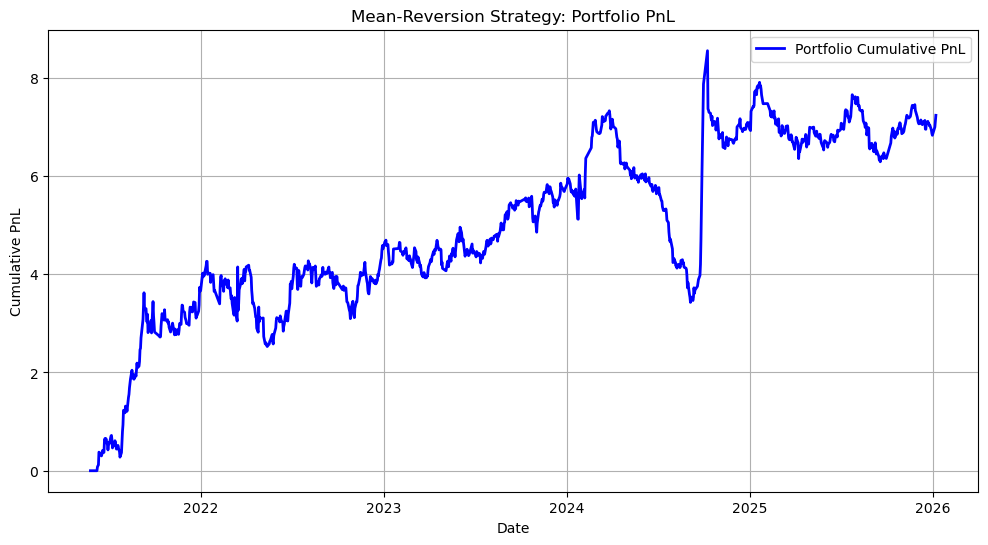

In [19]:
# --------------------------
# Print Metrics
# --------------------------
print(f"Number of stocks traded: {len(results)}")
print(f"Total Portfolio PnL: {total_pnl:.4f}")
print(f"Annualized Sharpe Ratio: {sharpe_ratio:.4f}")
print(f"Max Drawdown: {max_drawdown:.4f}")

# --------------------------
# Plot Portfolio Cumulative PnL
# --------------------------
plt.figure(figsize=(12,6))
plt.plot(portfolio_cum_pnl, label='Portfolio Cumulative PnL', color='blue', linewidth=2)
plt.title("Mean-Reversion Strategy: Portfolio PnL")
plt.xlabel("Date")
plt.ylabel("Cumulative PnL")
plt.grid(True)
plt.legend()
plt.show()